In [2]:
import pandas as pd

In [10]:
train = pd.read_csv("../data/UNSW_NB15_training-set.csv")
test = pd.read_csv("../data/UNSW_NB15_testing-set.csv")

In [11]:
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [12]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [13]:
train.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='str')

In [14]:
train["label"].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [15]:
train["attack_cat"].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [16]:
train.isnull().sum().sort_values(ascending=False).head(10)

id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
dtype: int64

In [17]:
train.duplicated().sum()

np.int64(0)

In [18]:
train["attack_cat"].isnull().sum()

np.int64(0)

In [19]:
train["proto"].value_counts().head(15)

proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
sun-nd      201
swipe       201
mobile      201
pim         201
ipv6        201
rsvp        200
sep         193
Name: count, dtype: int64

In [20]:
train["service"].value_counts()

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

In [21]:
train["state"].value_counts()

state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

In [22]:
train[["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate"]].describe()

,dur,spkts,dpkts,sbytes,dbytes,rate
count,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05
mean,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04
std,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05
min,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00
25%,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01
50%,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03
75%,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05
max,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06


In [23]:
train.groupby("label")[["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate"]].mean()

,dur,spkts,dpkts,sbytes,dbytes,rate
label,,,,,,
0,1.017177,30.725482,38.057696,4105.702929,31049.463143,13799.312118
1,1.519969,15.405946,10.012619,11068.655357,7364.456256,133699.690589


In [24]:
pd.crosstab(train["proto"], train["label"], normalize="index").sort_values(1, ascending=False).head(15)

label,0,1
proto,,
3pc,0.0,1.0
a/n,0.0,1.0
aes-sp3-d,0.0,1.0
any,0.0,1.0
argus,0.0,1.0
aris,0.0,1.0
ax.25,0.0,1.0
bbn-rcc,0.0,1.0
bna,0.0,1.0


In [25]:
train.groupby("proto")["label"].agg(["count", "mean"]).sort_values("count", ascending=False).head(15)

,count,mean
proto,,
tcp,79946,0.510657
udp,63283,0.780004
unas,12084,1.000000
arp,2859,0.000000
ospf,2595,0.975337
sctp,1150,1.000000
any,300,1.000000
gre,225,1.000000
swipe,201,1.000000


In [26]:
train.groupby("service")["label"].agg(["count", "mean"]).sort_values("count", ascending=False)

,count,mean
service,,
-,94168,0.612267
dns,47294,0.841566
http,18724,0.714377
smtp,5058,0.687821
ftp-data,3995,0.361202
ftp,3428,0.644691
ssh,1302,0.008449
pop3,1105,0.996380
dhcp,94,1.000000


In [27]:
pd.crosstab(train["attack_cat"], train["proto"]).loc[:, ["tcp", "udp", "unas", "arp", "ospf", "sctp"]]

proto,tcp,udp,unas,arp,ospf,sctp
attack_cat,,,,,,
Analysis,564,0,700,0,67,22
Backdoor,272,28,600,0,139,62
DoS,2281,358,4080,0,726,319
Exploits,19689,624,5280,0,1238,581
Fuzzers,11761,4945,600,0,141,64
Generic,486,39229,104,0,38,15
Normal,39121,13922,0,2859,64,0
Reconnaissance,5100,3586,720,0,182,87
Shellcode,557,576,0,0,0,0


<Axes: title={'center': 'Normal vs Attack Traffic'}, xlabel='label'>

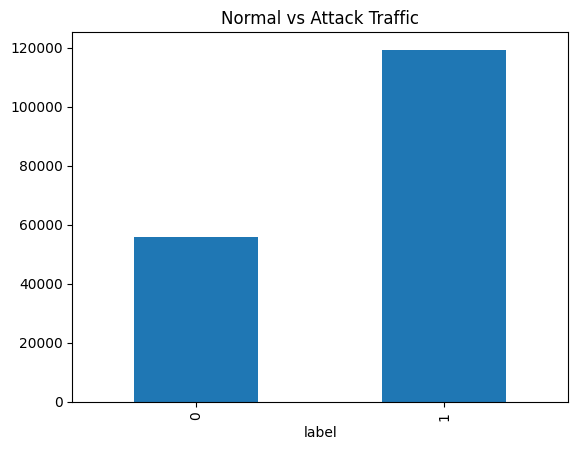

In [28]:
train["label"].value_counts().sort_index().plot(kind="bar", title="Normal vs Attack Traffic")

In [29]:
train.dtypes.value_counts()

int64      30
float64    11
str         4
Name: count, dtype: int64

In [30]:
train.select_dtypes(include="object").columns

C:\Users\mdsih\AppData\Local\Temp\ipykernel_11796\244920003.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.select_dtypes(include="object").columns


Index(['proto', 'service', 'state', 'attack_cat'], dtype='str')

In [31]:
test["label"].value_counts()

label
1    45332
0    37000
Name: count, dtype: int64

In [32]:
set(train.columns) == set(test.columns)

True

In [33]:
X_train = train.drop(columns=["label", "attack_cat"])
y_train = train["label"]

X_test = test.drop(columns=["label", "attack_cat"])
y_test = test["label"]

print(X_train.shape)
print(X_test.shape)

(175341, 43)
(82332, 43)


In [34]:
X_train.select_dtypes(include="str").columns

Index(['proto', 'service', 'state'], dtype='str')

In [35]:
from sklearn.preprocessing import OneHotEncoder

In [36]:
from sklearn.compose import ColumnTransformer

In [37]:
categorical_cols = ["proto", "service", "state"]

In [38]:
encoder = OneHotEncoder(handle_unknown="ignore")

In [40]:
encoder.fit(X_train[categorical_cols])

,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

In [41]:
encoder.get_feature_names_out(categorical_cols)

array(['proto_3pc', 'proto_a/n', 'proto_aes-sp3-d', 'proto_any',
       'proto_argus', 'proto_aris', 'proto_arp', 'proto_ax.25',
       'proto_bbn-rcc', 'proto_bna', 'proto_br-sat-mon', 'proto_cbt',
       'proto_cftp', 'proto_chaos', 'proto_compaq-peer', 'proto_cphb',
       'proto_cpnx', 'proto_crtp', 'proto_crudp', 'proto_dcn',
       'proto_ddp', 'proto_ddx', 'proto_dgp', 'proto_egp', 'proto_eigrp',
       'proto_emcon', 'proto_encap', 'proto_etherip', 'proto_fc',
       'proto_fire', 'proto_ggp', 'proto_gmtp', 'proto_gre', 'proto_hmp',
       'proto_i-nlsp', 'proto_iatp', 'proto_ib', 'proto_icmp',
       'proto_idpr', 'proto_idpr-cmtp', 'proto_idrp', 'proto_ifmp',
       'proto_igmp', 'proto_igp', 'proto_il', 'proto_ip', 'proto_ipcomp',
       'proto_ipcv', 'proto_ipip', 'proto_iplt', 'proto_ipnip',
       'proto_ippc', 'proto_ipv6', 'proto_ipv6-frag', 'proto_ipv6-no',
       'proto_ipv6-opts', 'proto_ipv6-route', 'proto_ipx-n-ip',
       'proto_irtp', 'proto_isis', 'proto_iso-ip'

In [42]:
X_train_encoded = encoder.transform(X_train[categorical_cols])

In [43]:
X_train_encoded.shape

(175341, 155)

In [44]:
X_test_encoded = encoder.transform(X_test[categorical_cols])

In [45]:
X_train_final = pd.concat(
    [X_train.drop(columns=categorical_cols).reset_index(drop=True),
     pd.DataFrame(X_train_encoded.toarray())],
    axis=1
)

In [46]:
X_train_final.shape

(175341, 195)

In [47]:
X_test_final = pd.concat(
    [X_test.drop(columns=categorical_cols).reset_index(drop=True),
     pd.DataFrame(X_test_encoded.toarray())],
    axis=1
)

In [48]:
X_test_final.shape

(82332, 195)

In [49]:
from sklearn.preprocessing import StandardScaler

In [50]:
scaler = StandardScaler()

In [52]:
X_train_final.columns = X_train_final.columns.astype(str)

In [53]:
X_train_scaled = scaler.fit_transform(X_train_final)

In [54]:
X_test_final.columns = X_test_final.columns.astype(str)

In [55]:
X_test_scaled = scaler.transform(X_test_final)

In [56]:
from sklearn.ensemble import RandomForestClassifier

In [57]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [58]:
rf_model.fit(X_train_scaled, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [59]:
y_pred = rf_model.predict(X_test_scaled)

In [60]:
from sklearn.metrics import accuracy_score

In [61]:
accuracy_score(y_test, y_pred)

0.6696059855220328

In [62]:
from sklearn.metrics import classification_report

In [63]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.62      0.69      0.65     37000
           1       0.72      0.65      0.68     45332

    accuracy                           0.67     82332
   macro avg       0.67      0.67      0.67     82332
weighted avg       0.68      0.67      0.67     82332



In [64]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred)

array([[25699, 11301],
       [15901, 29431]])

In [65]:
rf_model.feature_importances_

array([2.00978387e-01, 3.88997056e-02, 1.68822338e-02, 2.22471744e-02,
       2.81099950e-02, 1.84416117e-02, 4.49538548e-02, 5.15872527e-02,
       2.54040219e-02, 2.56306289e-02, 4.03230876e-02, 7.70358772e-03,
       4.24674857e-03, 2.41146718e-02, 2.90332102e-02, 1.69822173e-02,
       1.35160945e-02, 7.27264394e-03, 5.80488330e-03, 5.02762527e-03,
       2.05311717e-04, 2.72853588e-02, 2.19846490e-02, 2.02672569e-02,
       2.13523225e-02, 3.34192473e-02, 1.02564441e-03, 1.91819094e-03,
       1.68841049e-02, 9.45168522e-02, 6.84389377e-03, 4.69636345e-03,
       9.01562574e-03, 1.63963009e-02, 7.97203068e-05, 7.75266037e-05,
       1.20492725e-03, 6.71877433e-03, 2.17076000e-02, 7.48368044e-03,
       1.68782022e-06, 1.30715725e-08, 2.67654908e-08, 8.48777484e-06,
       2.49237315e-07, 3.10925663e-08, 8.60476039e-03, 6.68323141e-08,
       4.85517378e-08, 2.45052870e-07, 1.51075741e-08, 7.87548010e-06,
       2.71067296e-10, 2.34871000e-06, 2.23930814e-06, 1.65806244e-07,
      

In [66]:
pd.Series(rf_model.feature_importances_).sort_values(ascending=False).head(15)

0      0.200978
29     0.094517
7      0.051587
6      0.044954
10     0.040323
1      0.038900
25     0.033419
14     0.029033
4      0.028110
21     0.027285
9      0.025631
8      0.025404
13     0.024115
189    0.023147
3      0.022247
dtype: float64

In [67]:
pd.Series(X_train_final.columns).iloc[[0, 29, 7, 6, 10, 1, 25, 14, 4, 21, 9, 8, 13, 189, 3]]

0                id
29     ct_state_ttl
7              sttl
6              rate
10            dload
1               dur
25            dmean
14           dinpkt
4            sbytes
21           tcprtt
9             sload
8              dttl
13           sinpkt
189             149
3             dpkts
dtype: str

In [68]:
rf_model.feature_importances_[0]

np.float64(0.20097838689237313)

In [69]:
X_train_final = X_train_final.drop(columns=["0"])

In [70]:
X_train_final.shape

(175341, 194)

In [71]:
X_test_final = X_test_final.drop(columns=["0"])

In [72]:
X_train_final.shape

(175341, 194)

In [73]:
X_test_final.shape

(82332, 194)

In [74]:
X_train_scaled = scaler.fit_transform(X_train_final)

In [75]:
X_test_scaled = scaler.transform(X_test_final)

In [76]:
rf_model_no_id = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_no_id.fit(X_train_scaled, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [77]:
y_pred_no_id = rf_model_no_id.predict(X_test_scaled)

In [78]:
accuracy_score(y_test, y_pred_no_id)

0.7106106981489578

In [79]:
print(classification_report(y_test, y_pred_no_id))

              precision    recall  f1-score   support

           0       0.67      0.69      0.68     37000
           1       0.74      0.73      0.73     45332

    accuracy                           0.71     82332
   macro avg       0.71      0.71      0.71     82332
weighted avg       0.71      0.71      0.71     82332



In [80]:
confusion_matrix(y_test, y_pred_no_id)

array([[25565, 11435],
       [12391, 32941]])

In [81]:
pd.Series(
    rf_model_no_id.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False).head(15)

id              0.180765
ct_state_ttl    0.079259
sttl            0.052128
rate            0.048905
sload           0.039595
dload           0.038500
dbytes          0.037255
dttl            0.035498
dur             0.033195
ackdat          0.032086
synack          0.026596
dinpkt          0.023879
sjit            0.023194
ct_srv_dst      0.023054
sbytes          0.021234
dtype: float64

In [82]:
X_train_final.columns[:10]

Index(['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl',
       'dttl', 'sload'],
      dtype='str')

In [85]:
X_test_final = X_test_final.drop(columns=["id"])

In [86]:
X_train_final.shape

(175341, 193)

In [87]:
X_test_final.shape

(82332, 193)

In [88]:
X_train_scaled = scaler.fit_transform(X_train_final)

In [89]:
X_test_scaled = scaler.transform(X_test_final)

In [90]:
rf_model_clean = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_clean.fit(X_train_scaled, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [91]:
y_pred_clean = rf_model_clean.predict(X_test_scaled)

In [92]:
accuracy_score(y_test, y_pred_clean)

0.871204391973959

In [93]:
print(classification_report(y_test, y_pred_clean))

              precision    recall  f1-score   support

           0       0.98      0.73      0.84     37000
           1       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332



In [94]:
confusion_matrix(y_test, y_pred_clean)

array([[27065,  9935],
       [  669, 44663]])

In [95]:
pd.Series(
    rf_model_clean.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False).head(15)

sttl            0.097787
ct_state_ttl    0.072072
dload           0.059443
dttl            0.052482
ackdat          0.046004
rate            0.043549
sload           0.043119
dinpkt          0.042784
synack          0.035935
sbytes          0.035635
149             0.032780
dmean           0.029265
dur             0.027219
tcprtt          0.026643
ct_srv_dst      0.026181
dtype: float64

In [96]:
pd.Series(y_pred_clean).value_counts()

1    54598
0    27734
Name: count, dtype: int64

In [97]:
train[train["label"] == 1]["attack_cat"].value_counts()

attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [98]:
attack_train = train[train["label"] == 1].copy()

In [99]:
attack_train.shape

(119341, 45)

In [100]:
X_attack = attack_train.drop(columns=["label", "attack_cat"])

In [101]:
y_attack = attack_train["attack_cat"]

In [102]:
X_attack.select_dtypes(include="str").columns

Index(['proto', 'service', 'state'], dtype='str')

In [103]:
attack_encoder = OneHotEncoder(handle_unknown="ignore")

In [104]:
attack_encoder.fit(X_attack[["proto", "service", "state"]])

,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

In [105]:
X_attack_encoded = attack_encoder.transform(
    X_attack[["proto", "service", "state"]]
)

In [106]:
X_attack_encoded.shape

(119341, 147)

In [107]:
X_attack_final = pd.concat(
    [
        X_attack.drop(columns=["proto", "service", "state"]).reset_index(drop=True),
        pd.DataFrame(X_attack_encoded.toarray())
    ],
    axis=1
)

In [108]:
X_attack_final.shape

(119341, 187)

In [109]:
X_attack_final = X_attack_final.drop(columns=["id"])

In [110]:
X_attack_final.columns = X_attack_final.columns.astype(str)

In [111]:
attack_test = test[test["label"] == 1].copy()

In [112]:
X_attack_test = attack_test.drop(columns=["label", "attack_cat"])

In [113]:
y_attack_test = attack_test["attack_cat"]

In [114]:
X_attack_test_encoded = attack_encoder.transform(
    X_attack_test[["proto", "service", "state"]]
)

In [115]:
X_attack_test_final = pd.concat(
    [
        X_attack_test.drop(columns=["proto", "service", "state"]).reset_index(drop=True),
        pd.DataFrame(X_attack_test_encoded.toarray())
    ],
    axis=1
)

In [116]:
X_attack_test_final = X_attack_test_final.drop(columns=["id"])

In [117]:
X_attack_test_final.shape

(45332, 186)

In [118]:
y_attack_test.value_counts()

attack_cat
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

In [119]:
X_attack_test_encoded.shape

(45332, 147)

In [120]:
attack_scaler = StandardScaler()

In [121]:
X_attack_scaled = attack_scaler.fit_transform(X_attack_final)

In [123]:
X_attack_test_final.columns = X_attack_test_final.columns.astype(str)

In [124]:
X_attack_test_scaled = attack_scaler.transform(X_attack_test_final)

In [125]:
rf_attack = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [126]:
rf_attack.fit(X_attack_scaled, y_attack)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [127]:
y_attack_pred = rf_attack.predict(X_attack_test_scaled)

In [128]:
len(y_attack_pred)

45332

In [129]:
accuracy_score(y_attack_test, y_attack_pred)

0.7742654195711639

In [130]:
print(classification_report(y_attack_test, y_attack_pred))

                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       677
      Backdoor       0.02      0.08      0.03       583
           DoS       0.64      0.10      0.18      4089
      Exploits       0.64      0.80      0.71     11132
       Fuzzers       0.85      0.73      0.79      6062
       Generic       1.00      0.97      0.98     18871
Reconnaissance       0.93      0.80      0.86      3496
     Shellcode       0.48      0.67      0.56       378
         Worms       0.67      0.14      0.23        44

      accuracy                           0.77     45332
     macro avg       0.58      0.48      0.48     45332
  weighted avg       0.82      0.77      0.78     45332



In [131]:
confusion_matrix(y_attack_test, y_attack_pred)

array([[    2,   125,    16,   499,    35,     0,     0,     0,     0],
       [    2,    48,    16,   474,    40,     0,     0,     3,     0],
       [  336,  1350,   418,  1747,   165,     5,    27,    41,     0],
       [  352,  1248,   104,  8864,   344,     6,   153,    60,     1],
       [   41,   191,    36,  1209,  4439,     2,    11,   133,     0],
       [    0,     4,    40,   465,    74, 18271,     2,    14,     1],
       [   45,   178,    10,   396,    49,     0,  2799,    19,     0],
       [    0,     0,     9,    57,    56,     0,     3,   252,     1],
       [    0,     0,     0,    34,     3,     1,     0,     0,     6]])

In [132]:
rf_attack_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

In [133]:
rf_attack_balanced.fit(X_attack_scaled, y_attack)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [134]:
y_attack_pred_balanced = rf_attack_balanced.predict(X_attack_test_scaled)

In [135]:
accuracy_score(y_attack_test, y_attack_pred_balanced)

0.7535736345186623

In [136]:
print(classification_report(y_attack_test, y_attack_pred_balanced))

                precision    recall  f1-score   support

      Analysis       0.06      0.04      0.05       677
      Backdoor       0.05      0.54      0.09       583
           DoS       0.41      0.17      0.24      4089
      Exploits       0.84      0.63      0.72     11132
       Fuzzers       0.81      0.77      0.79      6062
       Generic       1.00      0.96      0.98     18871
Reconnaissance       0.87      0.84      0.85      3496
     Shellcode       0.36      0.83      0.50       378
         Worms       0.66      0.48      0.55        44

      accuracy                           0.75     45332
     macro avg       0.56      0.58      0.53     45332
  weighted avg       0.84      0.75      0.78     45332



In [137]:
confusion_matrix(y_attack_test, y_attack_pred_balanced)

array([[   27,   379,   106,    58,   107,     0,     0,     0,     0],
       [   27,   313,   116,     9,   110,     0,     1,     7,     0],
       [  140,  2346,   712,   549,   225,     1,    53,    61,     2],
       [  191,  2412,   479,  6964,   485,     1,   381,   214,     5],
       [   52,   780,   216,   122,  4697,     1,    14,   180,     0],
       [    6,    18,   101,   444,   103, 18172,     4,    20,     3],
       [   16,   292,    21,    99,    46,     0,  2943,    79,     0],
       [    0,     1,     4,     8,    48,     0,     4,   312,     1],
       [    0,     0,     1,    18,     4,     0,     0,     0,    21]])

In [138]:
feature_importance = pd.Series(
    rf_attack_balanced.feature_importances_,
    index=X_attack_final.columns
).sort_values(ascending=False)

feature_importance.head(15)

sbytes              0.107251
smean               0.096462
ct_dst_src_ltm      0.056086
ct_srv_dst          0.048329
sload               0.040586
ct_srv_src          0.036724
115                 0.033791
dbytes              0.030548
129                 0.030523
131                 0.027874
134                 0.025835
dmean               0.025132
ct_src_dport_ltm    0.024284
ct_dst_sport_ltm    0.023251
dur                 0.021258
dtype: float64

In [141]:
from sklearn.metrics import f1_score

In [142]:
f1_score(y_attack_test, y_attack_pred_balanced, average="macro")

0.5303508736133252

In [144]:
from sklearn.metrics import recall_score

In [145]:
recall_score(y_attack_test, y_attack_pred_balanced, average=None)

array([0.03988183, 0.53687822, 0.1741257 , 0.6255839 , 0.77482679,
       0.96295904, 0.84181922, 0.82539683, 0.47727273])

In [146]:
pd.Series(y_attack_pred_balanced).value_counts()

Generic           18175
Exploits           8271
Backdoor           6541
Fuzzers            5825
Reconnaissance     3400
DoS                1756
Shellcode           873
Analysis            459
Worms                32
Name: count, dtype: int64

In [147]:
pd.crosstab(
    y_attack_test,
    y_attack_pred_balanced
)

col_0,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Reconnaissance,Shellcode,Worms
attack_cat,,,,,,,,,
Analysis,27,379,106,58,107,0,0,0,0
Backdoor,27,313,116,9,110,0,1,7,0
DoS,140,2346,712,549,225,1,53,61,2
Exploits,191,2412,479,6964,485,1,381,214,5
Fuzzers,52,780,216,122,4697,1,14,180,0
Generic,6,18,101,444,103,18172,4,20,3
Reconnaissance,16,292,21,99,46,0,2943,79,0
Shellcode,0,1,4,8,48,0,4,312,1
Worms,0,0,1,18,4,0,0,0,21


In [148]:
y_attack.value_counts()

attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [149]:
from sklearn.utils.class_weight import compute_class_weight

In [152]:
import numpy as np

In [153]:
classes = sorted(y_attack.unique())
classes = np.array(classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_attack
)

In [154]:
dict(zip(classes, weights))

{np.str_('Analysis'): np.float64(6.630055555555556),
 np.str_('Backdoor'): np.float64(7.5945653557337405),
 np.str_('DoS'): np.float64(1.0812223671812713),
 np.str_('Exploits'): np.float64(0.39709253769086666),
 np.str_('Fuzzers'): np.float64(0.7292186048785256),
 np.str_('Generic'): np.float64(0.33150277777777776),
 np.str_('Reconnaissance'): np.float64(1.2639511115347546),
 np.str_('Shellcode'): np.float64(11.703540256938314),
 np.str_('Worms'): np.float64(102.0008547008547)}

In [155]:
import numpy as np

In [156]:
mild_weights = np.sqrt(weights)

In [157]:
dict(zip(classes, mild_weights))

{np.str_('Analysis'): np.float64(2.574889425889111),
 np.str_('Backdoor'): np.float64(2.755823897808737),
 np.str_('DoS'): np.float64(1.039818429910372),
 np.str_('Exploits'): np.float64(0.6301527891637604),
 np.str_('Fuzzers'): np.float64(0.8539429751912745),
 np.str_('Generic'): np.float64(0.5757627790833458),
 np.str_('Reconnaissance'): np.float64(1.1242558034249832),
 np.str_('Shellcode'): np.float64(3.421043737945821),
 np.str_('Worms'): np.float64(10.099547252271)}

In [158]:
mild_weight_dict = dict(zip(classes, mild_weights))

In [159]:
rf_attack_mild = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight=mild_weight_dict
)

In [160]:
rf_attack_mild.fit(X_attack_scaled, y_attack)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.str_('Analysis'): np.float64(2.574889425889111), np.str_('Backdoor'): np.float64(2.755823897808737), np.str_('DoS'): np.float64(1.039818429910372), np.str_('Exploits'): np.float64(0.6301527891637604), ...}"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not

In [161]:
y_attack_pred_mild = rf_attack_mild.predict(X_attack_test_scaled)

In [162]:
accuracy_score(y_attack_test, y_attack_pred_mild)

0.7631253860407659

In [163]:
from sklearn.metrics import f1_score
f1_score(y_attack_test, y_attack_pred_mild, average="macro")

0.49891447568712827

In [164]:
from sklearn.metrics import classification_report

print(classification_report(y_attack_test, y_attack_pred_balanced))

                precision    recall  f1-score   support

      Analysis       0.06      0.04      0.05       677
      Backdoor       0.05      0.54      0.09       583
           DoS       0.41      0.17      0.24      4089
      Exploits       0.84      0.63      0.72     11132
       Fuzzers       0.81      0.77      0.79      6062
       Generic       1.00      0.96      0.98     18871
Reconnaissance       0.87      0.84      0.85      3496
     Shellcode       0.36      0.83      0.50       378
         Worms       0.66      0.48      0.55        44

      accuracy                           0.75     45332
     macro avg       0.56      0.58      0.53     45332
  weighted avg       0.84      0.75      0.78     45332

